# Exercise 3.3

In this compressed sensing will be tested on a random generated dataset, following the Fourier basis.

In [2]:
# Import relevant modules
import numpy as np
from cosamp import cosamp
from scipy.fft import ifft
import matplotlib.pyplot as plt

## a)

A dataset of 1000 inputs is created based on a K = 5 sparse vector of Fourier coefficients.

In [11]:
# Create 5-spare Fourier coefficients and find basis
# Copilot has created the data construction code
n, K = 1000, 5
rng = np.random.default_rng(42)  # for reproducibility

s = np.zeros(n, dtype=complex)
indices = rng.choice(n, size=K, replace=False)
s[indices] = rng.standard_normal(K) + 1j * rng.standard_normal(K)

print("Nonzero entries in frequency domain:", np.count_nonzero(s))

# Fourier basis id obtained from the inverse FFT to create x
Psi = ifft(np.eye(n), axis=0, norm="ortho")

x = Psi @ s
print("Number of non zero inputs in time domain: ", len(x))

Nonzero entries in frequency domain: 5
Number of non zero inputs in time domain:  1000


Now a random measurement matrix, following a Gaussian distribution, is made, where p = 1 ... 100, to increase the complexity of the measurements.

For each p, the measurements, y, are found and the compressed sensing algorithm cosamp, is used to estimate the Fourier coefficients, shat. This is done 10 times for each p.

To evaluate the accuracy of the measurements the average relative 2-norm is found. Also the 1-norm and 0-norm is found for all iterations.

The errors as a function of p are plotted.

/Users/dittejuhler-nottrup/Documents/GitHub/data_driven/Exercises/cosamp.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  b[omega], _, _, _ = np.linalg.lstsq(phiT, u)


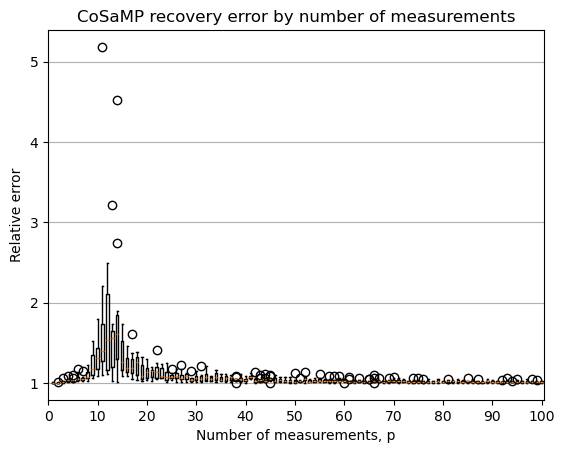

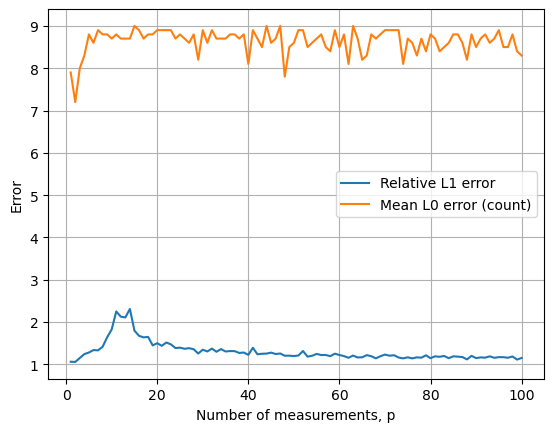

In [13]:
p_list = np.arange(1, 101)
num_runs = 10

errors = np.zeros((len(p_list), num_runs))
errors_l1 = np.zeros(len(p_list))
errors_l0 = np.zeros(len(p_list))


for p_idx, p in enumerate(p_list):
    # For each measurement size, run 10 times
    l1 = np.zeros(num_runs)
    l0 = np.zeros(num_runs)
    for run in range(num_runs):
        # Create a p-by-n Gaussian sensor matrix
        C = rng.standard_normal((p, n))
        y = C @ x

        ## Solve compressed sensing problem
        Theta = C @ Psi

        shat = cosamp(Theta, y, K, epsilon=1e-10, max_iter = 10)

        errors[p_idx, run] = np.linalg.norm(shat - s) / np.linalg.norm(s)

        diff = shat - s
        l1[run] = np.linalg.norm(diff, ord=1) / np.linalg.norm(s, ord=1)

        l0[run] = np.count_nonzero(diff>1e-10)

    errors_l1[p_idx] = np.mean(l1)
    errors_l0[p_idx] = np.mean(l0)
    


# One box per p, showing the distribution across its 10 runs
plt.figure()
plt.boxplot(errors.T, positions=p_list)
plt.xlabel("Number of measurements, p")
plt.ylabel("Relative error")
plt.title("CoSaMP recovery error by number of measurements")
plt.xticks(np.arange(0, 101, 10), np.arange(0, 101, 10))
plt.grid(axis="y")
plt.show()

plt.plot(p_list, errors_l1, label="Relative L1 error")
plt.plot(p_list, errors_l0, label="Mean L0 error (count)")
plt.xlabel("Number of measurements, p")
plt.ylabel("Error")
plt.legend()
plt.grid(True)
plt.show()


The plots show that the average relative error increases until around 20-30 measurements are made. Then it is seen that the errors "stabilize" and are not very spread out. This shows that when fewer measurements are made, even though the error might be small, it is not as stable. It also shows that the error does not decrease significantly after 30 measurements are made, however the variance does decrease.

It can be seen from the l0 error, that even though the relative error decreaseas, the count of signals differeing is relatively stable. When looking at the l1 error, it shows that the total error is decreasing. This must mean that the coefficients at the true indexes become closer to each other, even though there might still be non-zero coefficients in the estimates, which should be zero.


## b)

Now the same experiment is tested for K = 1 to K = 20

/Users/dittejuhler-nottrup/Documents/GitHub/data_driven/Exercises/cosamp.py:26: ComplexWarning: Casting complex values to real discards the imaginary part
  b[omega], _, _, _ = np.linalg.lstsq(phiT, u)


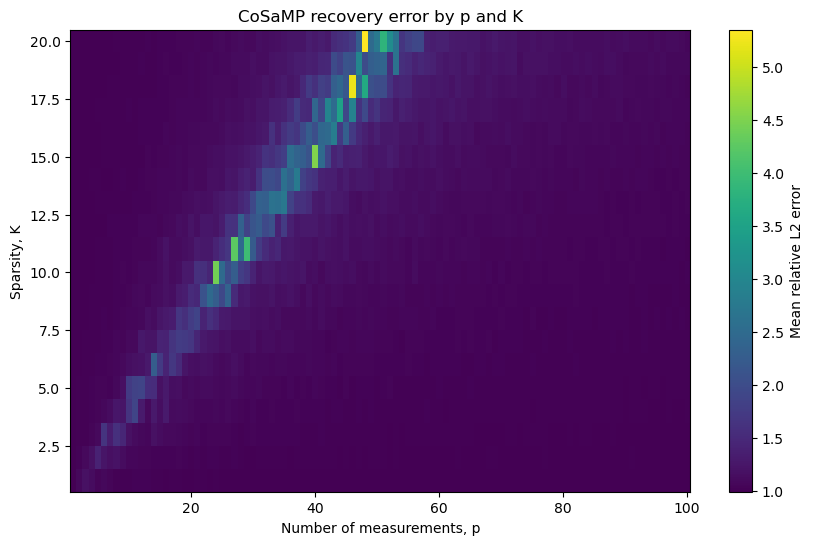

In [14]:
p_list = np.arange(1, 101)
K_list = np.arange(1, 21)
num_runs = 10

# Axes: K, p, run
errors_by_K = np.zeros((len(K_list), len(p_list), num_runs))
errors_l1_by_K = np.zeros((len(K_list), len(p_list)))
errors_l0_by_K = np.zeros((len(K_list), len(p_list)))

for k_idx, K in enumerate(K_list):
    
    indices = rng.choice(n, size=K, replace=False)
    s[indices] = rng.standard_normal(K) + 1j * rng.standard_normal(K)

    # Fourier basis id obtained from the inverse FFT to create x
    Psi = ifft(np.eye(n), axis=0, norm="ortho")
    x = Psi @ s

    for p_idx, p in enumerate(p_list):
        # For each measurement size, run 10 times
        l1 = np.zeros(num_runs)
        l0 = np.zeros(num_runs)
        for run in range(num_runs):
            # Create a p-by-n Gaussian sensor matrix
            C = rng.standard_normal((p, n))
            y = C @ x

            ## Solve compressed sensing problem
            Theta = C @ Psi

            shat = cosamp(Theta, y, K,epsilon=1e-10, max_iter = 10)

            diff = shat - s

            errors_by_K[k_idx, p_idx, run] = np.linalg.norm(shat - s) / np.linalg.norm(s)

            l1[run] = np.linalg.norm(diff, ord=1) / np.linalg.norm(s, ord=1)

            l0[run] = np.count_nonzero(diff>0)

        errors_l1_by_K[k_idx, p_idx] = np.mean(l1)

        errors_l0_by_K[k_idx, p_idx] = np.mean(l0)    


mean_errors = errors_by_K.mean(axis=2)

plt.figure(figsize=(10, 6))
plt.imshow(
    mean_errors,
    origin="lower",
    aspect="auto",
    extent=[
        p_list[0] - 0.5, p_list[-1] + 0.5,
        K_list[0] - 0.5, K_list[-1] + 0.5,
    ],
    interpolation="nearest",
)
plt.colorbar(label="Mean relative L2 error")
plt.xlabel("Number of measurements, p")
plt.ylabel("Sparsity, K")
plt.title("CoSaMP recovery error by p and K")
plt.show()

This plot shows, that as the sparsity, K, increases, the mean relative error as a function og measurements also increases. This is perhaps intuitive, as the less sparse / the more complex s becomes, the more measurements (on average) is needed to describe it accurately.

## c)

Now the experiment is repeated, where K = 5 and the number of inputs in x differ.

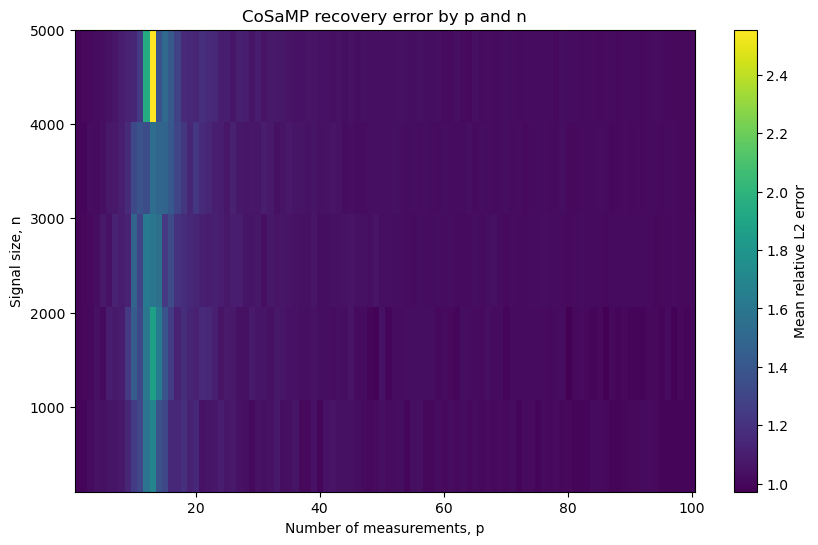

In [15]:
p_list = np.arange(1, 101)
K = 5
num_runs = 10

n_list = [100, 500, 1000, 2000, 5000]

# Axes: n, p, run
errors_by_n = np.zeros((len(n_list), len(p_list), num_runs))
errors_l1_by_n = np.zeros((len(n_list), len(p_list)))
errors_l0_by_n = np.zeros((len(n_list), len(p_list)))

for n_idx, n in enumerate(n_list):

    s = np.zeros(n, dtype=complex)
    indices = rng.choice(n, size=K, replace=False)
    s[indices] = rng.standard_normal(K) + 1j * rng.standard_normal(K)

    # Fourier basis id obtained from the inverse FFT to create x
    Psi = ifft(np.eye(n), axis=0, norm="ortho")
    x = Psi @ s

    for p_idx, p in enumerate(p_list):
        # For each measurement size, run 10 times
        l1 = np.zeros(num_runs)
        l0 = np.zeros(num_runs)
        for run in range(num_runs):
            # Create a p-by-n Gaussian sensor matrix
            C = rng.standard_normal((p, n))
            y = C @ x

            ## Solve compressed sensing problem
            Theta = C @ Psi

            shat = cosamp(Theta, y, K, epsilon = 1.e-10, max_iter = 10)

            diff = shat - s

            errors_by_n[n_idx, p_idx, run] = np.linalg.norm(shat - s) / np.linalg.norm(s)

            l1[run] = np.linalg.norm(diff, ord=1) / np.linalg.norm(s, ord=1)

            l0[run] = np.count_nonzero(diff>0)

        errors_l1_by_n[n_idx, p_idx] = np.mean(l1)

        errors_l0_by_n[n_idx, p_idx] = np.mean(l0)    


mean_errors = errors_by_n.mean(axis=2)

plt.figure(figsize=(10, 6))
plt.imshow(
    mean_errors,
    origin="lower",
    aspect="auto",
    extent=[
        p_list[0] - 0.5, p_list[-1] + 0.5,
        n_list[0] - 0.5, n_list[-1] + 0.5,
    ],
    interpolation="nearest",
)
plt.colorbar(label="Mean relative L2 error")
plt.xlabel("Number of measurements, p")
plt.ylabel("Signal size, n")
plt.title("CoSaMP recovery error by p and n")
plt.show()

This plot shows, that when the number of signals increase, the realative error is stable in regards to the number of measurements. This means that even though the number of samples increase, as long as the sparsity remains at K = 5, the relative error is pretty constant regarding the number of measurements. It is not the total number of samples, which determine the number of measurements needed, as this is more dependent on the sparsity of the system.